# part 1: data exploration and preprocessing

This notebook audits the real merged dataset, explores it, creates leakage-free past features, and saves development data, a future test year, and validation folds. It does not train a forecasting model.

We import simple libraries and fix the random seed so that the notebook is reproducible.

In [1]:
from pathlib import Path
import json
import random
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, GroupKFold, KFold

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

project_root = Path.cwd()
if not (project_root / "data").exists():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))
data_dir = project_root / "data"
processed_dir = data_dir / "processed"
results_dir = project_root / "results"
figures_dir = project_root / "figures"
folds_dir = project_root / "folds"
processed_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
folds_dir.mkdir(parents=True, exist_ok=True)
print("python version:", sys.version.split()[0])
from src.preprocessing import load_combined_data


python version: 3.10.5


The project folder has three CSV files. The combined file already contains PM2.5 and the GEE variables in the same rows, so it is the most suitable starting file.

In [2]:
source = data_dir / "raw" / "combined_gee_pm25.csv"
df = load_combined_data(source)
print("source file:", source)
print("kaggle source: https://www.kaggle.com/datasets/sarahameziane/air-quality-mediterranean-basin20162026/")
print("license: not found in the project files, to check on the kaggle page")
print("shape:", df.shape)
print("columns:", list(df.columns))
display(df.head())

source file: C:\Users\LENOVO\Documents\ds project\data\raw\combined_gee_pm25.csv
kaggle source: https://www.kaggle.com/datasets/sarahameziane/air-quality-mediterranean-basin20162026/
license: not found in the project files, to check on the kaggle page
shape: (41718, 15)
columns: ['date', 'datetime_utc', 'id', 'latitude', 'longitude', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD', 'pm25', 'sensor_name']


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name
0,2016-11-25,2016-11-25 00:00:00,1,38.788056,-0.697222,6.493180,946.288660,0.230240,0.735303,NaN,NaN,NaN,0.1110,2.750000,ONTINYENT
1,2016-11-25,2016-11-25 00:00:00,36,39.945278,-0.056389,9.251236,993.626994,0.783218,-0.592618,NaN,NaN,NaN,0.0220,11.666667,ALMASSORA-C. P. OCHANDO
2,2016-11-30,2016-11-30 00:00:00,35,40.051944,-0.189722,10.044782,981.911432,-2.211047,-1.568971,NaN,NaN,NaN,0.2380,2.400000,ALCORA
3,2016-11-30,2016-11-30 00:00:00,37,40.062222,0.072778,12.299584,1008.794766,-3.236886,-2.804465,NaN,NaN,NaN,0.2480,2.600000,BENICASSIM
4,2016-12-02,2016-12-02 00:00:00,1,38.788056,-0.697222,9.350630,953.114180,0.953454,0.293060,NaN,NaN,NaN,0.0755,2.750000,ONTINYENT


This table shows the real data types. I do not add names for variables that are not present in the file.

In [3]:
print(df.dtypes)
print("date range as text:", df["date"].min(), "to", df["date"].max())
print("numeric columns:", list(df.select_dtypes(include="number").columns))
print("units: pm25 is micrograms per cubic metre from the project brief; temperature is celsius; pressure is mb; other units are not given in the files")

date                    object
datetime_utc            object
id                       int64
latitude               float64
longitude              float64
temperature_celsius    float64
pressure_mb            float64
wind_u                 float64
wind_v                 float64
NO2                    float64
CO                     float64
O3                     float64
AOD                    float64
pm25                   float64
sensor_name             object
dtype: object
date range as text: 2016-11-25 to 2026-04-06
numeric columns: ['id', 'latitude', 'longitude', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD', 'pm25']
units: pm25 is micrograms per cubic metre from the project brief; temperature is celsius; pressure is mb; other units are not given in the files


I parse both date columns and check whether parsing creates invalid timestamps. The separate `datetime_utc` column is consistent with the daily `date` column in this file.

In [4]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"], errors="coerce")
print("invalid date values:", df["date"].isna().sum())
print("invalid datetime values:", df["datetime_utc"].isna().sum())
print("date range:", df["date"].min().date(), "to", df["date"].max().date())
print("latitude range:", df["latitude"].min(), "to", df["latitude"].max())
print("longitude range:", df["longitude"].min(), "to", df["longitude"].max())
print("sensor names:", df["sensor_name"].nunique(), "and numeric ids:", df["id"].nunique())

invalid date values: 0
invalid datetime values: 0
date range: 2016-11-25 to 2026-04-06
latitude range: 36.13331699932336 to 43.5302972250095
longitude range: -5.663499999930786 to 9.136389000276088
sensor names: 94 and numeric ids: 98


The coordinate ranges are plausible for the Mediterranean study area. The numeric `id` is a GEE location identifier, while `sensor_name` identifies the repeated PM2.5 station observations. I will use `sensor_name` for station grouping because it is the air-quality station label.

We count missing values and duplicate keys before cleaning. This gives a baseline for the audit.

In [5]:
missing = pd.DataFrame({"count": df.isna().sum()})
missing["percentage"] = 100 * missing["count"] / len(df)
display(missing)
print("full-row duplicates:", df.duplicated().sum())
key_columns = ["date", "latitude", "longitude", "sensor_name"]
print("duplicates on date, coordinates and sensor name:", df.duplicated(key_columns).sum())
print("observations per sensor summary:")
display(df.groupby("sensor_name").size().describe())

,count,percentage
date,0,0.000000
datetime_utc,0,0.000000
id,0,0.000000
latitude,0,0.000000
longitude,0,0.000000
temperature_celsius,0,0.000000
pressure_mb,0,0.000000
wind_u,0,0.000000
wind_v,0,0.000000
NO2,2410,5.776883


full-row duplicates: 0


duplicates on date, coordinates and sensor name: 0
observations per sensor summary:


count      94.000000
mean      443.808511
std       284.020796
min         1.000000
25%       199.500000
50%       464.000000
75%       680.000000
max      1047.000000
dtype: float64

There are repeated measurements from the same stations. This means rows are not independent, so spatial grouped validation is needed later. Missingness is present for NO2, CO, and O3 and will be handled inside a training-fold pipeline later.

The PM2.5 cleaning rules come from the project brief. I report each removal reason separately before changing the data.

In [6]:
initial_rows = len(df)
missing_pm25 = df["pm25"].isna()
invalid_low = df["pm25"].notna() & (df["pm25"] <= 0)
invalid_high = df["pm25"].notna() & (df["pm25"] >= 500)
cleaning_counts = pd.DataFrame({
    "reason": ["initial rows", "missing pm25", "pm25 <= 0", "pm25 >= 500"],
    "rows": [initial_rows, int(missing_pm25.sum()), int(invalid_low.sum()), int(invalid_high.sum())]
})
display(cleaning_counts)

,reason,rows
0,initial rows,41718
1,missing pm25,0
2,pm25 <= 0,727
3,pm25 >= 500,8


Rows with missing or invalid PM2.5 cannot be targets for this task, so I remove them. Exact duplicate rows are also removed. Key duplicates were zero, so no repeated station-day measurements need a special aggregation decision.

In [7]:
keep = ~(missing_pm25 | invalid_low | invalid_high)
clean = df.loc[keep].copy()
exact_duplicates = int(clean.duplicated().sum())
clean = clean.drop_duplicates().copy()
clean = clean.sort_values(["sensor_name", "date"]).reset_index(drop=True)
cleaning_counts = pd.concat([cleaning_counts, pd.DataFrame({"reason": ["exact duplicates after invalid-row removal", "final cleaned rows"], "rows": [exact_duplicates, len(clean)]})], ignore_index=True)
display(cleaning_counts)

,reason,rows
0,initial rows,41718
1,missing pm25,0
2,pm25 <= 0,727
3,pm25 >= 500,8
4,exact duplicates after invalid-row removal,0
5,final cleaned rows,40983


The invalid PM2.5 sentinels are removed, but large valid values below 500 are kept. A high value can be a real pollution episode rather than a measurement error.

I create a long tidy audit table. Each row has one variable, one metric, and one value so that the different results fit in one CSV file.

In [8]:
audit_rows = []
for column in df.columns:
    audit_rows.append({"section": "audit", "variable": column, "metric": "missing_count", "value": float(df[column].isna().sum())})
    audit_rows.append({"section": "audit", "variable": column, "metric": "missing_percentage", "value": float(100 * df[column].isna().mean())})
for row in cleaning_counts.itertuples(index=False):
    audit_rows.append({"section": "cleaning", "variable": "pm25", "metric": row.reason, "value": float(row.rows)})
audit_rows.append({"section": "audit", "variable": "dataset", "metric": "rows", "value": float(len(df))})
audit_rows.append({"section": "audit", "variable": "dataset", "metric": "columns", "value": float(df.shape[1])})
audit_rows.append({"section": "audit", "variable": "sensor_name", "metric": "unique_stations", "value": float(clean["sensor_name"].nunique())})
audit_rows.append({"section": "audit", "variable": "date", "metric": "unique_dates", "value": float(clean["date"].nunique())})
exploratory = pd.DataFrame(audit_rows)

I summarize the numeric variables with the statistics requested in the brief. Identifiers and coordinates are shown for audit, but they will not be model features.

In [9]:
numeric_columns = clean.select_dtypes(include="number").columns.tolist()
numeric_summary = clean[numeric_columns].describe().T
numeric_summary["skewness"] = clean[numeric_columns].skew()
numeric_summary["kurtosis"] = clean[numeric_columns].kurtosis()
display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
id,40983.0,52.725032,35.034045,0.000000,21.000000,50.000000,90.000000,109.000000,0.102677,-1.513270
latitude,40983.0,39.030362,2.231117,36.133317,36.841330,39.448330,40.051944,43.530297,0.396995,-0.686293
longitude,40983.0,-0.466409,3.829059,-5.663500,-3.612660,-0.406050,1.149600,9.136389,0.643840,0.158251
temperature_celsius,40983.0,18.271961,6.386195,-1.279053,12.965739,18.494734,23.787869,34.865831,-0.102340,-0.971192
pressure_mb,40983.0,993.817385,17.180014,930.317065,987.986366,997.728716,1005.366821,1033.662176,-1.086888,0.714344
wind_u,40983.0,0.343444,2.527802,-11.098723,-0.984837,0.205846,1.684241,9.661651,-0.177789,1.034201
wind_v,40983.0,-0.178770,1.385553,-10.860048,-0.730883,0.042730,0.661478,8.486383,-1.276639,4.389013
NO2,38576.0,0.000092,0.000027,0.000023,0.000075,0.000086,0.000101,0.000483,2.122683,9.177522
CO,38576.0,0.031578,0.003893,0.013058,0.029041,0.031412,0.033827,0.097613,1.398186,13.768381
O3,38535.0,0.143550,0.014491,0.103899,0.134019,0.140472,0.151048,0.229322,1.150540,2.278098


The target distribution is usually right-skewed in pollution data. I show its shape, its log1p version for inspection only, and the shares above the two project thresholds.

pm25 skewness: 17.82910231943009
share above 25: 2.98 %
share above 50: 0.29 %


,count,median,mean,std
season,,,,
autumn,10003,7.470000,9.082521,12.019754
spring,9276,6.833333,8.251462,7.402640
summer,12766,8.500000,9.593868,7.210516
winter,8938,8.773333,10.935249,11.722205


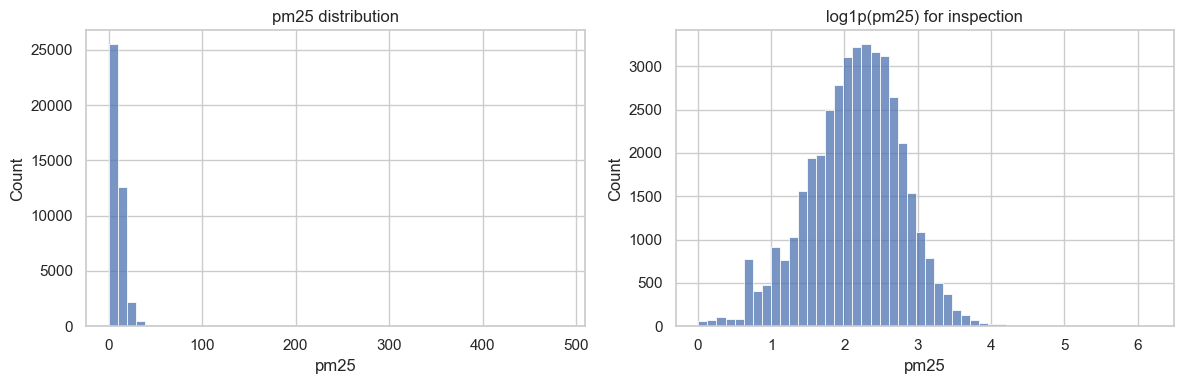

In [10]:
clean["month"] = clean["date"].dt.month
clean["year"] = clean["date"].dt.year
clean["season"] = clean["month"].map({12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring", 6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"})
print("pm25 skewness:", clean["pm25"].skew())
print("share above 25:", round(100 * (clean["pm25"] > 25).mean(), 2), "%")
print("share above 50:", round(100 * (clean["pm25"] > 50).mean(), 2), "%")
display(clean.groupby("season")["pm25"].agg(["count", "median", "mean", "std"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(clean["pm25"], bins=50, ax=axes[0])
axes[0].set_title("pm25 distribution")
sns.histplot(np.log1p(clean["pm25"]), bins=50, ax=axes[1])
axes[1].set_title("log1p(pm25) for inspection")
plt.tight_layout()
plt.savefig(figures_dir / "pm25_distribution.png", dpi=150)
plt.show()

A skewed target means RMSE will give extra weight to large errors, while MAE is less dominated by extreme days. We should keep the extreme episodes visible and report both metrics in the modeling part.

These quick plots compare the main real variables named in the project brief. Only columns that actually exist are selected.

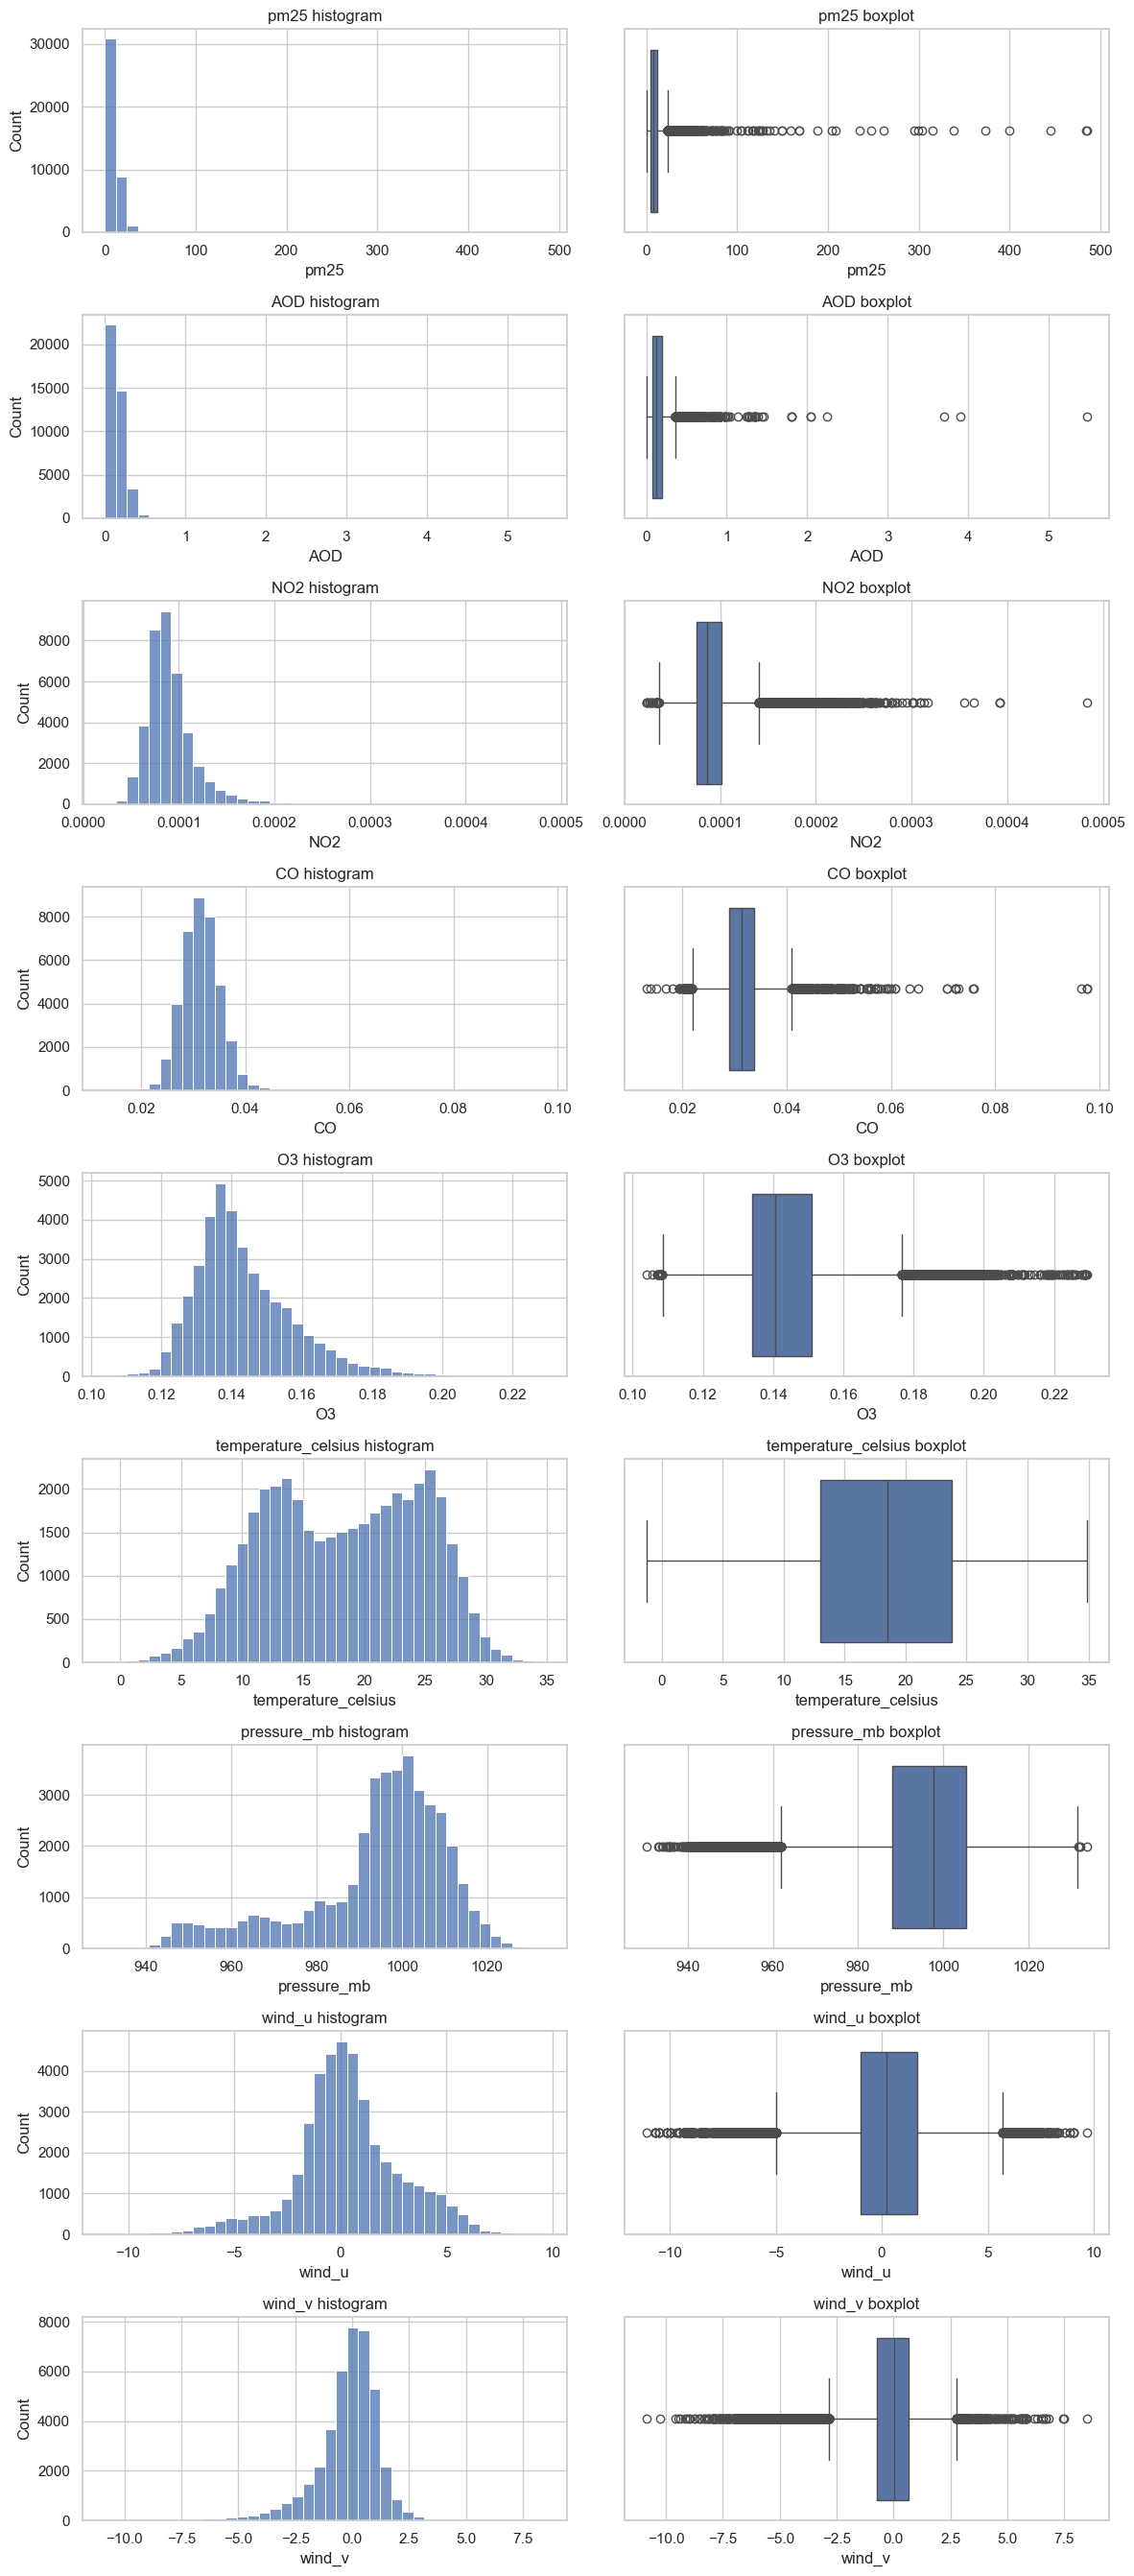

In [11]:
plot_columns = ["pm25", "AOD", "NO2", "CO", "O3", "temperature_celsius", "pressure_mb", "wind_u", "wind_v"]
plot_columns = [column for column in plot_columns if column in clean.columns]
fig, axes = plt.subplots(len(plot_columns), 2, figsize=(12, 3 * len(plot_columns)))
for row, column in enumerate(plot_columns):
    sns.histplot(clean[column], bins=40, ax=axes[row, 0])
    axes[row, 0].set_title(column + " histogram")
    sns.boxplot(x=clean[column], ax=axes[row, 1])
    axes[row, 1].set_title(column + " boxplot")
plt.tight_layout()
plt.savefig(figures_dir / "main_variables_histograms_boxplots.png", dpi=150)
plt.show()

The boxplots are for inspection, not automatic deletion. A large PM2.5 value is retained if it passes the documented validity rule.

I use the IQR rule, z-scores, and Isolation Forest to flag unusual PM2.5 values. These flags describe the data and do not remove observations.

In [12]:
q1 = clean["pm25"].quantile(0.25)
q3 = clean["pm25"].quantile(0.75)
iqr = q3 - q1
iqr_flag = (clean["pm25"] < q1 - 1.5 * iqr) | (clean["pm25"] > q3 + 1.5 * iqr)
z_flag = zscore(clean["pm25"].to_numpy()) > 3
isolation = IsolationForest(random_state=SEED, contamination="auto")
isolation_flag = isolation.fit_predict(clean[["pm25"]]) == -1
print("IQR flagged:", int(iqr_flag.sum()))
print("absolute z-score above 3:", int(np.abs(zscore(clean["pm25"].to_numpy())) .gt if False else (np.abs(zscore(clean["pm25"].to_numpy())) > 3).sum()))
print("Isolation Forest flagged:", int(isolation_flag.sum()))

IQR flagged: 1613
absolute z-score above 3: 255
Isolation Forest flagged: 6952


The IQR, z-score, and Isolation Forest methods answer different questions and can flag legitimate pollution episodes. I keep all valid PM2.5 values because deleting them would bias the future model toward ordinary days.

I calculate Pearson and Spearman correlations among numeric predictors. The target is excluded from the predictor-pair list used for multicollinearity checks.

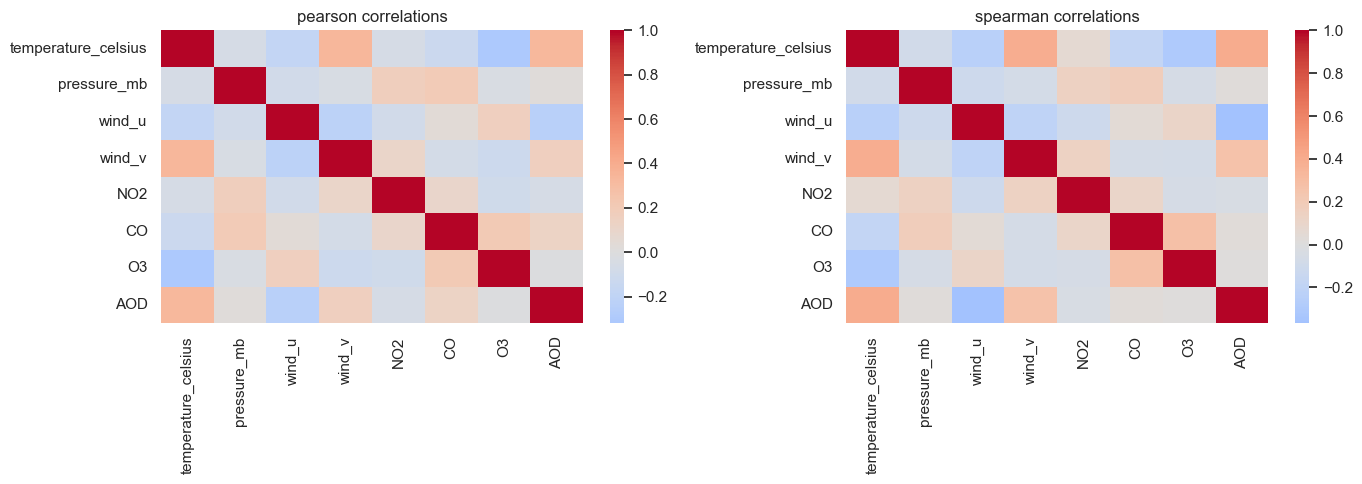

""


In [13]:
excluded = ["pm25", "id", "latitude", "longitude", "month", "year"]
predictor_numeric = [column for column in clean.select_dtypes(include="number").columns if column not in excluded]
pearson = clean[predictor_numeric].corr(method="pearson")
spearman = clean[predictor_numeric].corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pearson, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("pearson correlations")
sns.heatmap(spearman, cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("spearman correlations")
plt.tight_layout()
plt.savefig(figures_dir / "correlation_heatmaps.png", dpi=150)
plt.show()
high_pairs = []
for i, first in enumerate(predictor_numeric):
    for second in predictor_numeric[i + 1:]:
        value = pearson.loc[first, second]
        if abs(value) > 0.9:
            high_pairs.append({"first": first, "second": second, "pearson": value})
display(pd.DataFrame(high_pairs))

VIF is another multicollinearity diagnostic. I fill missing predictor values with medians only for this descriptive calculation; this is not the modeling pipeline and is not used to train a model.

In [14]:
vif_data = clean[predictor_numeric].copy()
vif_data = vif_data.fillna(vif_data.median())
vif_table = pd.DataFrame({"variable": vif_data.columns})
vif_table["vif"] = [variance_inflation_factor(vif_data.to_numpy(), i) for i in range(vif_data.shape[1])]
display(vif_table)

,variable,vif
0,temperature_celsius,1.394638
1,pressure_mb,1.077777
2,wind_u,1.143657
3,wind_v,1.185729
4,NO2,1.078783
5,CO,1.139174
6,O3,1.191216
7,AOD,1.236333


I compare PM2.5 with AOD and inspect whether the AOD relationship changes between low and high wind. This is descriptive and does not claim causality.

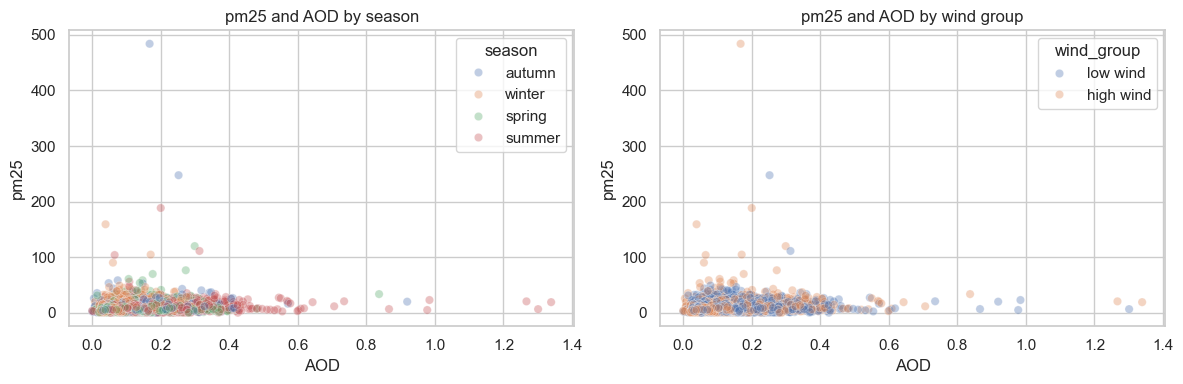

correlation by wind group


wind_group      
low wind    pm25    0.069112
high wind   pm25    0.109277
Name: AOD, dtype: float64

In [15]:
clean["wind_speed"] = np.sqrt(clean["wind_u"] ** 2 + clean["wind_v"] ** 2)
clean["wind_group"] = pd.qcut(clean["wind_speed"], q=2, labels=["low wind", "high wind"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=clean.sample(min(5000, len(clean)), random_state=SEED), x="AOD", y="pm25", hue="season", alpha=0.35, ax=axes[0])
axes[0].set_title("pm25 and AOD by season")
sns.scatterplot(data=clean.sample(min(5000, len(clean)), random_state=SEED), x="AOD", y="pm25", hue="wind_group", alpha=0.35, ax=axes[1])
axes[1].set_title("pm25 and AOD by wind group")
plt.tight_layout()
plt.savefig(figures_dir / "pm25_predictor_relationships.png", dpi=150)
plt.show()
print("correlation by wind group")
display(clean.groupby("wind_group", observed=True)[["pm25", "AOD"]].corr().loc[(slice(None), "pm25"), "AOD"])

I create a long tidy audit table. Each row has one variable, one metric, and one value so that the different results fit in one CSV file.

In [16]:
audit_rows = []
for column in df.columns:
    audit_rows.append({"section": "audit", "variable": column, "metric": "missing_count", "value": float(df[column].isna().sum())})
    audit_rows.append({"section": "audit", "variable": column, "metric": "missing_percentage", "value": float(100 * df[column].isna().mean())})
for row in cleaning_counts.itertuples(index=False):
    audit_rows.append({"section": "cleaning", "variable": "pm25", "metric": row.reason, "value": float(row.rows)})
audit_rows.append({"section": "audit", "variable": "dataset", "metric": "rows", "value": float(len(df))})
audit_rows.append({"section": "audit", "variable": "dataset", "metric": "columns", "value": float(df.shape[1])})
audit_rows.append({"section": "audit", "variable": "sensor_name", "metric": "unique_stations", "value": float(clean["sensor_name"].nunique())})
audit_rows.append({"section": "audit", "variable": "date", "metric": "unique_dates", "value": float(clean["date"].nunique())})
exploratory = pd.DataFrame(audit_rows)

I summarize the numeric variables with the statistics requested in the brief. Identifiers and coordinates are shown for audit, but they will not be model features.

In [17]:
numeric_columns = clean.select_dtypes(include="number").columns.tolist()
numeric_summary = clean[numeric_columns].describe().T
numeric_summary["skewness"] = clean[numeric_columns].skew()
numeric_summary["kurtosis"] = clean[numeric_columns].kurtosis()
display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
id,40983.0,52.725032,35.034045,0.000000,21.000000,50.000000,90.000000,109.000000,0.102677,-1.513270
latitude,40983.0,39.030362,2.231117,36.133317,36.841330,39.448330,40.051944,43.530297,0.396995,-0.686293
longitude,40983.0,-0.466409,3.829059,-5.663500,-3.612660,-0.406050,1.149600,9.136389,0.643840,0.158251
temperature_celsius,40983.0,18.271961,6.386195,-1.279053,12.965739,18.494734,23.787869,34.865831,-0.102340,-0.971192
pressure_mb,40983.0,993.817385,17.180014,930.317065,987.986366,997.728716,1005.366821,1033.662176,-1.086888,0.714344
wind_u,40983.0,0.343444,2.527802,-11.098723,-0.984837,0.205846,1.684241,9.661651,-0.177789,1.034201
wind_v,40983.0,-0.178770,1.385553,-10.860048,-0.730883,0.042730,0.661478,8.486383,-1.276639,4.389013
NO2,38576.0,0.000092,0.000027,0.000023,0.000075,0.000086,0.000101,0.000483,2.122683,9.177522
CO,38576.0,0.031578,0.003893,0.013058,0.029041,0.031412,0.033827,0.097613,1.398186,13.768381
O3,38535.0,0.143550,0.014491,0.103899,0.134019,0.140472,0.151048,0.229322,1.150540,2.278098


I build the two required exploration CSV files. The temporal table contains the main timestamp, regularity, drift, and diagnostic values.

In [18]:
for column in numeric_columns:
    if column in clean.columns:
        for metric in ["min", "max", "mean", "std", "25%", "50%", "75%", "skewness", "kurtosis"]:
            if metric in numeric_summary.columns:
                exploratory.loc[len(exploratory)] = ["numeric_summary", column, metric, float(numeric_summary.loc[column, metric])]
for column in ["NO2", "CO", "O3"]:
    for month, group in clean.groupby("month"):
        exploratory.loc[len(exploratory)] = ["missing_by_month", column, "month_" + str(month), float(group[column].isna().sum())]
    for station, group in clean.groupby("sensor_name"):
        exploratory.loc[len(exploratory)] = ["missing_by_station", column, station, float(group[column].isna().sum())]
exploratory.to_csv(results_dir / "Exploratory_Data.csv", index=False, encoding="utf-8", decimal=".")
